<a href="https://colab.research.google.com/github/SoulDataLab/CODSOFT_TASKSNO/blob/main/CodSoft_Task2_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

# Styling set karna
sns.set_theme(style="whitegrid")

# File upload karwana agar session naya hai
print("Please upload your 'cleaned_marketing_campaign.csv' file:")
uploaded = files.upload()

# Dataset load karna
file_path = "cleaned_marketing_campaign.csv"
df = pd.read_csv(file_path)

print("Dataset successfully loaded for EDA!")
print(f"Shape: {df.shape}")
display(df.head(3))

Please upload your 'cleaned_marketing_campaign.csv' file:


Saving cleaned_marketing_campaign.csv to cleaned_marketing_campaign.csv
Dataset successfully loaded for EDA!
Shape: (2053, 27)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,10,4,7,0,0,0,0,0,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,1,2,5,0,0,0,0,0,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,2,10,4,0,0,0,0,0,0,0


In [4]:
print("=== NUMERICAL FEATURES SUMMARY ===")
display(df.describe())

print("\n=== CATEGORICAL FEATURES SUMMARY ===")
display(df.describe(include=['object']))

=== NUMERICAL FEATURES SUMMARY ===


,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,...,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response
count,2053.000000,2053.000000,2053.000000,2053.000000,2053.000000,2053.000000,2053.000000,2053.000000,2053.000000,2053.000000,...,2053.000000,2053.000000,2053.000000,2053.000000,2053.000000,2053.000000,2053.000000,2053.000000,2053.000000,2053.000000
mean,5597.635168,1968.880175,52345.807112,0.445689,0.509498,48.986849,304.123721,26.220653,167.796883,37.351680,...,2.663419,5.775938,5.320994,0.073551,0.076961,0.071603,0.065757,0.012664,0.009255,0.151973
std,3254.140575,11.663962,25393.119679,0.537663,0.546594,28.977159,336.602044,39.701807,228.323134,54.689323,...,2.934837,3.240440,2.440068,0.261102,0.266594,0.257891,0.247918,0.111849,0.095779,0.359082
min,0.000000,1940.000000,1730.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2811.000000,1959.000000,35701.000000,0.000000,0.000000,24.000000,23.000000,1.000000,16.000000,3.000000,...,0.000000,3.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,5512.000000,1970.000000,51381.500000,0.000000,0.000000,49.000000,174.000000,8.000000,67.000000,12.000000,...,2.000000,5.000000,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,8442.000000,1977.000000,68274.000000,1.000000,1.000000,74.000000,504.000000,33.000000,230.000000,50.000000,...,4.000000,8.000000,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,11191.000000,1996.000000,666666.000000,2.000000,2.000000,99.000000,1493.000000,199.000000,1725.000000,259.000000,...,28.000000,13.000000,20.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000



=== CATEGORICAL FEATURES SUMMARY ===


,Education,Marital_Status,Dt_Customer
count,2053,2053,2053
unique,5,5,663
top,Graduation,Married,02-01-2013
freq,1029,795,9


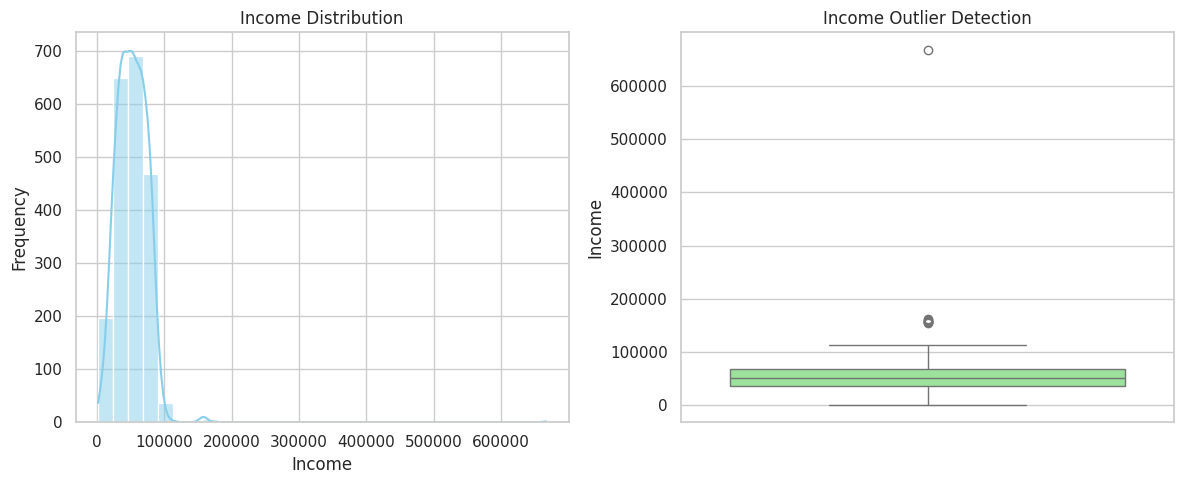

In [5]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(df['Income'].dropna(), bins=30, kde=True, color='skyblue')
plt.title('Income Distribution')
plt.xlabel('Income')
plt.ylabel('Frequency')

plt.subplot(1, 2, 2)
sns.boxplot(y=df['Income'].dropna(), color='lightgreen')
plt.title('Income Outlier Detection')
plt.ylabel('Income')

plt.tight_layout()
plt.show()

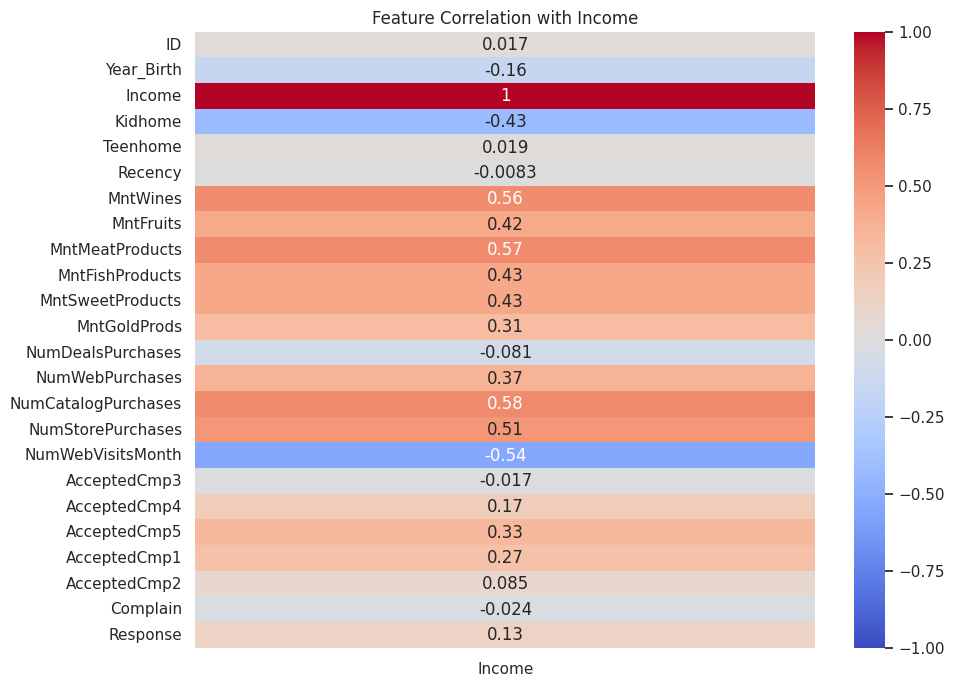

In [6]:
# Sirf numerical columns ka correlation nikalna
numerical_cols = df.select_dtypes(include=[np.number]).columns
correlation_matrix = df[numerical_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix[['Income']], annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Feature Correlation with Income')
plt.show()

In [7]:
# Summary stats ko CSV mein save karna
summary_stats = df.describe()
summary_stats.to_csv("eda_summary_statistics.csv", index=True)
print("EDA summary statistics successfully saved as 'eda_summary_statistics.csv'.")

EDA summary statistics successfully saved as 'eda_summary_statistics.csv'.
